# 05 – ACT-NER: residual refinement and validation experiments

Can learned span-level corrections improve exact typed recognition with frozen biomedical experts? The experiment separates model fitting, epoch/threshold selection, calibration and outer evaluation by document dependency groups. Estimates condition on the historically selected upstream models; no test observations enter this notebook.

In [1]:
from pathlib import Path
import os, sys, json, time
PROJECT_ROOT=Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
for _folder in ("artifacts", "figures/PNG", "figures/PDF", "Models", "Predictions", "Reports"):
    (PROJECT_ROOT / _folder).mkdir(parents=True, exist_ok=True)    # output folders of a fresh clone
assert (PROJECT_ROOT/"dataset").is_dir()
sys.path.insert(0,str(PROJECT_ROOT/"src"))
os.environ["HF_HUB_OFFLINE"]="1"
os.environ["TOKENIZERS_PARALLELISM"]="false"
import numpy as np
import pandas as pd
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML
assert "Times New Roman" in {font.name for font in font_manager.fontManager.ttflist}
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,
    "axes.titlesize":20,"axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,
    "legend.fontsize":18,"figure.dpi":350,"savefig.dpi":350,"figure.facecolor":"white"})
pd.set_option("display.max_rows",None)
pd.set_option("display.max_columns",None)
pd.set_option("display.max_colwidth",None)
torch.set_num_threads(4)

## Executable architecture and training objective

Candidate union → contextual span features → context/sequence/prototype residuals → sparse routing → span verifier and subtype classifier. Frozen probabilities initialize residual logits; expert membership never overrides a learned prediction. Calibration is fitted after predictive training.

In [2]:
from dataclasses import replace
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from prospective_model import ACTNER as SpanNetwork
from prospective_model import tensor_batch, composite_loss, score, strict_metrics
from core import finalize_prediction_frame
from models import set_seed

In [3]:
class ACTNER(SpanNetwork):
    def __init__(self, config):
        super().__init__(config)
        for layer in (self.span_head, self.type_head):
            nn.init.normal_(layer.weight, std=0.001)
            nn.init.zeros_(layer.bias)

    @torch.no_grad()
    def initialize_prototypes(self, bundle, indices, device):
        # An excluded context expert must not survive in prototype initialization.
        if self.config.use_transformer_expert and self.config.use_prototype_expert:
            super().initialize_prototypes(bundle, indices, device)

    def forward(self, batch):
        output = super().forward(batch)
        experts = []
        if self.config.use_transformer_expert:
            experts.append(batch["transformer"])
        if self.config.use_crf_expert:
            experts.append(batch["crf"])
        boundary = torch.stack([value[:, 1] for value in experts]).mean(0)
        subtype = torch.stack([value[:, -4:] for value in experts]).mean(0)
        output["span_logits"] = output["span_logits"] + torch.logit(boundary.clamp(1e-5, 1 - 1e-5))
        output["type_logits"] = output["type_logits"] + subtype.clamp_min(1e-5).log()
        return output

In [4]:
def eligible_candidates(frame, config):
    """A fixed union isolates learned components from candidate coverage."""
    return frame.generated_candidate.to_numpy(dtype=bool, copy=True)

In [5]:
def training_indices(bundle, document_ids, config, seed):
    frame = bundle.frame
    allowed = frame.document_id.isin(document_ids).to_numpy() & eligible_candidates(frame, config)
    positive = np.flatnonzero(allowed & frame.span_label.eq(1).to_numpy())
    negative = np.flatnonzero(allowed & frame.span_label.eq(0).to_numpy())
    rng = np.random.default_rng(seed)
    limit = min(len(negative), config.hard_negative_ratio * len(positive))
    if config.hard_negative_mining:
        evidence = (["transformer_span_score"] if config.use_transformer_expert else [])
        evidence += ["crf_span_score"] if config.use_crf_expert else []
        hardness = frame.iloc[negative][evidence].max(axis=1).to_numpy()
        negative = negative[np.argsort(-(hardness + rng.uniform(0, 1e-6, len(negative))))[:limit]]
    else:
        negative = rng.choice(negative, limit, replace=False)
    return np.concatenate([positive, negative])

In [6]:
def decode(scores, sentences, config, threshold, seed, split="Validation"):
    selected = scores.loc[eligible_candidates(scores, config) & scores.span_probability.ge(threshold)]
    emitted = []
    for _, group in selected.groupby("sentence_id", sort=False):
        occupied = []
        group = group.sort_values(["entity_probability", "char_start", "char_end"], ascending=[False, True, True])
        for row in group.itertuples(index=False):
            if any(row.char_start < right and left < row.char_end for left, right in occupied):
                continue
            occupied.append((row.char_start, row.char_end))
            emitted.append({"document_id": row.document_id, "sentence_id": row.sentence_id,
                "char_start": int(row.char_start), "char_end": int(row.char_end),
                "token_start": int(row.token_start), "token_end": int(row.token_end),
                "predicted_type": row.predicted_type, "boundary_probability": row.span_probability,
                "type_probability": row.type_probability})
    result = finalize_prediction_frame(emitted, sentences, "ACT-NER", split, seed)
    result["calibrated_confidence"] = result.boundary_probability * result.type_probability
    assert result.entity_id.is_unique
    return result

In [7]:
def select_threshold(scores, sentences, entities, config, seed, grid):
    table = pd.DataFrame([{"threshold": threshold,
        **strict_metrics(entities, decode(scores, sentences, config, threshold, seed))} for threshold in grid])
    selected = table.sort_values(["typed_f1", "boundary_f1", "typed_recall", "macro_f1", "threshold"],
                                 ascending=[False, False, False, False, True]).iloc[0]
    return float(selected.threshold), table

In [8]:
def component_ablations(config):
    """One scientific mechanism per refit; inactive controls are not ablations."""
    variants = {
        "Without Context Expert": {"use_transformer_expert": False},
        "Without Sequence Expert": {"use_crf_expert": False},
        "Without Prototype Expert": {"use_prototype_expert": False},
        "Static routing": {"static_average": True},
        "Without orthographic residual": {"use_orthographic": False},
        "Without lexical reliability": {"use_lexical_reliability": False},
        "Without weak-signal recovery": {"weak_signal_recovery": False},
        "Without hard-negative mining": {"hard_negative_mining": False},
        "Without class balancing": {"class_balanced_type_loss": False},
        "Without source balancing": {"source_balancing": "none"},
        "Without domain adapter": {"domain_adapter": False},
        "Without router regularization": {"router_regularization": False},
        "Parameter-matched span MLP": {"parameter_matched_control": True},
    }
    return {name: replace(config, **change) for name, change in variants.items()}

In [9]:
def fit_model(bundle, selection_bundle, training_ids, sentences, entities,
              config, seed, settings, callback=None):
    set_seed(seed)
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    model = ACTNER(config).to(device)
    positions = training_indices(bundle, training_ids, config, seed)
    rows = bundle.frame.iloc[positions]
    assert not set(rows.document_id) & set(sentences.document_id)
    model.initialize_prototypes(bundle, positions, device)
    labels = rows.type_label.to_numpy(int)
    counts = torch.tensor(np.maximum(np.bincount(labels[labels >= 0], minlength=4), 1),
                          dtype=torch.float32, device=device)
    weights = 1 / rows.document_id.map(rows.document_id.value_counts()).to_numpy(float)
    if config.source_balancing == "balanced_sampler":
        sources = rows[["document_id", "source"]].drop_duplicates().source.value_counts()
        weights /= rows.source.map(sources).to_numpy(float)
    if config.class_balanced_type_loss:
        weights *= np.where(np.isin(labels, [1, 3]), 2.0, 1.0)
    weights /= weights.sum()
    adapter = list(model.context_adapter.parameters())
    adapter_ids = {id(value) for value in adapter}
    other = [value for value in model.parameters() if value.requires_grad and id(value) not in adapter_ids]
    optimizer = torch.optim.AdamW([{"params": adapter, "lr": settings["learning_rate"] / 2},
        {"params": other, "lr": settings["learning_rate"]}], weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    best, stale, history, state = -1.0, 0, [], None
    started = time.perf_counter()
    for epoch in range(1, settings["max_epochs"] + 1):
        model.train()
        sampled = rng.choice(positions, len(positions), replace=True, p=weights)
        losses, terms = [], []
        for start in range(0, len(sampled), settings["batch_size"]):
            batch = tensor_batch(bundle, sampled[start:start + settings["batch_size"]], device)
            optimizer.zero_grad(set_to_none=True)
            loss, component = composite_loss(model, batch, model(batch), counts)
            assert torch.isfinite(loss)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"])
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
            terms.append(component)
        scores, _ = score(model, selection_bundle)
        threshold, tuning = select_threshold(scores, sentences, entities, config, seed,
                                             settings["threshold_grid"])
        metric = float(tuning.typed_f1.max())
        row = {"epoch": epoch, "train_loss": float(np.mean(losses)),
               "selection_typed_f1": metric, "threshold": threshold,
               **pd.DataFrame(terms).mean().to_dict()}
        history.append(row)
        if callback:
            callback(row)
        if metric > best + 1e-6:
            best, stale, best_threshold, best_epoch = metric, 0, threshold, epoch
            state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
        if stale >= settings["patience"]:
            break
    assert state is not None
    model.load_state_dict(state)
    return model, pd.DataFrame(history), best_threshold, best_epoch, time.perf_counter() - started

In [10]:
import hashlib
import json
import shutil
import time
from dataclasses import asdict, replace
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import torch
from scipy import stats
from core import ENTITY_TYPES, PREDICTION_COLUMNS, gold_for_metrics, load_processed, normalize_surface
from act_ner import ACTNERConfig, build_candidate_bundle
from prospective_data import dependency_components, group_folds, split_group_holdout
from prospective_experiments import annotate_candidates, save_bundle
from prospective_model import score, strict_metrics
from prospective_calibration import apply_confidence, fit_confidence_bundle, candidate_targets, ece
from refinement_model import ACTNER, fit_model, component_ablations, decode

In [11]:
RUN = "refinement_20260907"

In [12]:
SEEDS = (17, 29, 43)

In [13]:
SETTINGS = {"max_epochs": 8, "patience": 3, "batch_size": 512,
            "learning_rate": 0.001, "gradient_clip": 1.0,
            "threshold_grid": [0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]}

In [14]:
CALIBRATION = {"methods": ["identity", "temperature", "platt"],
               "selection_folds": 3, "min_positive_and_negative": 10}

In [15]:
MODELS = {"O-only": "o_only", "Longest-match lexicon": "longest_match_lexicon",
          "Logistic Regression": "logistic_regression", "Linear-chain CRF": "linear_chain_crf",
          "BiLSTM-CRF": "bilstm_crf", "Biomedical Transformer": "biomedical_transformer"}

In [16]:
def digest(path):
    result = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(2**20), b""):
            result.update(chunk)
    return result.hexdigest()

In [17]:
def initialize_run(root, force_rebuild_proposed=True, reuse_proposed_cache=False):
    assert force_rebuild_proposed and not reuse_proposed_cache
    directory = root / "Reports" / RUN
    directory.mkdir(exist_ok=True)
    protected = []
    for prefix in ("Models/Baselines", "Models/Comparators", "Predictions/OOF", "Predictions/Validation"):
        protected.extend(p for p in (root / prefix).rglob("*") if p.is_file())
    protected.extend(p for p in (root / "notebooks").glob("0[1-4]*.ipynb"))
    contract = {str(p.relative_to(root)): digest(p) for p in protected}
    path = directory / "protected.json"
    if path.exists():
        assert json.loads(path.read_text()) == contract
    else:
        path.write_text(json.dumps(contract, indent=2))
    archive = directory / "before"
    archive.mkdir(exist_ok=True)
    for path in [*(root / "notebooks").glob("0[56]*.ipynb"), *(root / "Models/Proposed").glob("*.*")]:
        destination = archive / path.name
        if not destination.exists():
            shutil.copy2(path, destination)
    protocol = {"run": RUN, "seeds": list(SEEDS), "outer_folds": 5, "settings": SETTINGS,
        "selection": "Inner document holdout only; best mean inner typed F1 across three seeds",
        "final_seed": 17, "test_role": "Post-hoc Diagnostic Test",
        "upstream_scope": "Historical frozen experts; conditional validation evidence, not independent upstream model selection",
        "architecture": "Trainable residual logits; no anchor override; sparse tri-expert span verifier and type classifier",
        "calibration": CALIBRATION, "gold": "Contiguous, offset_valid; no oracle candidates",
        "ablation_estimand": "Learned evidence contribution conditional on the same frozen candidate union; not total removal of upstream candidate generators",
        "model_source_sha256": digest(root / "src/refinement_model.py"),
        "base_source_sha256": digest(root / "src/prospective_model.py")}
    protocol_path = directory / "protocol.json"
    if protocol_path.exists():
        assert json.loads(protocol_path.read_text()) == protocol
    else:
        protocol_path.write_text(json.dumps(protocol, indent=2))
    (root / "Models/Proposed" / RUN).mkdir(exist_ok=True)
    model_directory = root / "Models/Proposed" / RUN
    if any(model_directory.iterdir()):
        previous = directory / "previous_runs" / str(time.time_ns())
        previous.mkdir(parents=True)
        shutil.move(str(model_directory), str(previous / "models"))
        model_directory.mkdir()
        for item in [*directory.glob("fold_*.csv"), *directory.glob("selection_fold_*.csv"),
                     root / "src/refinement_freeze.json"]:
            if item.exists():
                shutil.move(str(item), str(previous / item.name))
    return directory

In [18]:
def verify_protected(root):
    contract = json.loads((root / "Reports" / RUN / "protected.json").read_text())
    assert all(digest(root / path) == value for path, value in contract.items())

In [19]:
def development(root):
    sentences, entities, tokens = load_processed(root, "validation")
    gold = gold_for_metrics(entities)
    assert sentences.sentence_id.is_unique and gold.entity_id.is_unique
    documents = sentences[["document_id", "source"]].drop_duplicates().sort_values("document_id")
    documents["dependency_group"] = documents.document_id.map(dependency_components(sentences))
    presence = gold.groupby(["document_id", "entity_type"]).size().unstack(fill_value=0)
    documents["stratum"] = [f"{r.source}|{int(presence.loc[r.document_id].get('brand', 0)>0)}|"
        f"{int(presence.loc[r.document_id].get('drug_n', 0)>0)}" if r.document_id in presence.index else r.source
        for r in documents.itertuples()]
    documents["outer_fold"] = documents.document_id.map(group_folds(documents, 5, 1701))
    membership = root / "Reports" / RUN / "membership.csv"
    if membership.exists():
        pd.testing.assert_frame_equal(pd.read_csv(membership), documents.reset_index(drop=True))
    else:
        documents.to_csv(membership, index=False)
    return sentences, entities, tokens, documents

In [20]:
def role_partition(documents, fold):
    outer = set(documents.loc[documents.outer_fold == fold, "document_id"]) if fold >= 0 else set()
    available = documents.loc[~documents.document_id.isin(outer)]
    grow, calibration = split_group_holdout(available, 0.2, 2301 + fold * 10)
    train, selection = split_group_holdout(available.loc[available.document_id.isin(grow)], 0.2, 2302 + fold * 10)
    roles = {"train": train, "selection": selection, "calibration": calibration, "outer": outer}
    assert set.union(*roles.values()) == set(documents.document_id)
    assert sum(map(len, roles.values())) == len(documents)
    group_sets = {k: set(documents.loc[documents.document_id.isin(v), "dependency_group"]) for k,v in roles.items()}
    assert sum(map(len, group_sets.values())) == len(set.union(*group_sets.values()))
    return roles

In [21]:
def subset_bundle(bundle, identifiers):
    return bundle.subset(np.flatnonzero(bundle.frame.document_id.isin(identifiers)))

In [22]:
def generate_evidence(root, sentences, entities, tokens):
    # Candidate generation receives no gold labels. Targets are joined afterward.
    bundle, _, elapsed = build_candidate_bundle(root, sentences, entities.iloc[:0], tokens, 0.72)
    assert bundle.frame.generated_candidate.all()
    bundle = annotate_candidates(bundle, entities)
    cache = root / "dataset/Interim" / RUN / "validation"
    save_bundle(bundle, cache)
    gold = gold_for_metrics(entities)
    truth = set(zip(gold.sentence_id, gold.char_start, gold.char_end))
    rows = []
    for name, mask in [("Transformer", bundle.frame.origin_transformer),
                       ("CRF", bundle.frame.origin_crf), ("Candidate union", bundle.frame.generated_candidate)]:
        part = bundle.frame.loc[mask]
        keys = set(zip(part.sentence_id, part.char_start, part.char_end))
        rows.append({"Source": name, "N": len(truth), "Candidates": len(keys), "Boundary recall": len(keys & truth)/len(truth)})
    result = pd.DataFrame(rows)
    assert result.iloc[-1]["Boundary recall"] >= result.iloc[:-1]["Boundary recall"].max()
    return bundle, result, elapsed

In [23]:
def configurations():
    base = ACTNERConfig(continual_adaptation=False, lambda_consistency=0.0,
        shift_triggered=False, boundary_threshold=0.5, use_lexical_reliability=True)
    return {"Joint-A": replace(base, dropout=0.10, gate_hidden_size=128, type_loss="effective_number"),
            "Joint-B": replace(base, dropout=0.15, gate_hidden_size=192, type_loss="focal"),
            "Joint-C": replace(base, dropout=0.25, gate_hidden_size=256, type_loss="logit_adjusted")}

In [24]:
def fit_unit(root, bundle, sentences, entities, roles, fold, name, config, seed, callback=None):
    safe_name = name.lower().replace(" ", "_")
    target = root / "Models/Proposed" / RUN / f"fold_{fold}" / safe_name / f"seed_{seed}"
    target.mkdir(parents=True, exist_ok=True)
    assert not (target / "model.pt").exists(), "This experiment must be a fresh fit, not a historical replay"
    select_sentences = sentences.loc[sentences.document_id.isin(roles["selection"])]
    select_entities = entities.loc[entities.document_id.isin(roles["selection"])]
    train_bundle = subset_bundle(bundle, roles["train"])
    select_bundle = subset_bundle(bundle, roles["selection"])
    model, history, threshold, epoch, elapsed = fit_model(train_bundle, select_bundle, roles["train"],
        select_sentences, select_entities, config, seed, SETTINGS, callback)
    checkpoint = {"state_dict": {k:v.detach().cpu() for k,v in model.state_dict().items()},
        "config": asdict(config), "threshold": threshold, "seed": seed, "epoch": epoch,
        "run": RUN, "roles": {k:sorted(v) for k,v in roles.items()}, "trained_at_ns": time.time_ns()}
    torch.save(checkpoint, target / "model.pt")
    history.to_csv(target / "history.csv", index=False)
    info = {"configuration": name, "seed": seed, "fold": fold, "threshold": threshold,
            "selection_typed_f1": float(history.selection_typed_f1.max()), "epoch": epoch,
            "training_seconds": elapsed, "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "checkpoint": str((target / "model.pt").relative_to(root))}
    (target / "fit.json").write_text(json.dumps(info, indent=2))
    return model, info, target

In [25]:
def prediction_diagnostics(prediction, entities):
    truth = gold_for_metrics(entities)
    keys = set(zip(truth.sentence_id, truth.char_start, truth.char_end, truth.entity_type))
    correct = np.array([key in keys for key in prediction[["sentence_id","char_start","char_end","predicted_type"]].itertuples(index=False,name=None)])
    confidence = prediction.calibrated_confidence.to_numpy(float)
    raw = (prediction.boundary_probability * prediction.type_probability).to_numpy(float)
    return {"ece": ece(confidence, correct), "raw_ece": ece(raw, correct),
            "brier": float(np.mean((confidence-correct)**2)) if len(correct) else np.nan}

In [26]:
def evaluate_unit(model, bundle, sentences, entities, documents, roles, seed, target):
    calibration_bundle = subset_bundle(bundle, roles["calibration"])
    calibration_scores, _ = score(model, calibration_bundle)
    calibration_docs = documents.loc[documents.document_id.isin(roles["calibration"])]
    mapping, calibration_table = fit_confidence_bundle(calibration_scores, calibration_docs, CALIBRATION)
    joblib.dump(mapping, target / "calibrator.joblib")
    calibration_table.to_csv(target / "calibration.csv", index=False)
    evaluation = subset_bundle(bundle, roles["outer"])
    scores, elapsed = score(model, evaluation)
    observed_sentences = sentences.loc[sentences.document_id.isin(roles["outer"])]
    observed_entities = entities.loc[entities.document_id.isin(roles["outer"])]
    threshold = json.loads((target / "fit.json").read_text())["threshold"]
    prediction = decode(scores, observed_sentences, model.config, threshold, seed, "Validation cross-fit")
    prediction = apply_confidence(prediction, mapping)
    prediction.to_parquet(target / "predictions.parquet", index=False)
    scores.to_parquet(target / "scores.parquet", index=False)
    metric = {**strict_metrics(observed_entities, prediction), **prediction_diagnostics(prediction, observed_entities),
              "head_inference_seconds": elapsed, "sentences": len(observed_sentences)}
    return prediction, scores, metric

In [27]:
def nested_fold(root, bundle, sentences, entities, documents, fold, callback=None):
    original_frame = bundle.frame.copy(deep=True)
    roles = role_partition(documents, fold)
    candidates, fitted, selection = configurations(), {}, []
    for name, config in candidates.items():
        for seed in SEEDS:
            report = (lambda row, n=name, s=seed: callback(fold,n,s,row)) if callback else None
            model, info, target = fit_unit(root,bundle,sentences,entities,roles,fold,name,config,seed,report)
            fitted[(name,seed)] = (info,target)
            selection.append(info)
            del model
    selection_table = pd.DataFrame(selection)
    means = selection_table.groupby("configuration").selection_typed_f1.mean()
    selected = str(means.sort_values(ascending=False, kind="stable").index[0])
    selection_table.to_csv(root / "Reports" / RUN / f"selection_fold_{fold}.csv", index=False)
    variants = {"Full ACT-NER": candidates[selected], **component_ablations(candidates[selected])}
    results = []
    for name, config in variants.items():
        for seed in SEEDS:
            if name == "Full ACT-NER":
                info, target = fitted[(selected,seed)]
                model = load_model(target / "model.pt")
            else:
                report = (lambda row, n=name, s=seed: callback(fold,n,s,row)) if callback else None
                model, info, target = fit_unit(root,bundle,sentences,entities,roles,fold,name,config,seed,report)
            _, _, metrics = evaluate_unit(model,bundle,sentences,entities,documents,roles,seed,target)
            results.append({**info, **metrics, "configuration":name, "selected_joint":selected})
            del model
    table = pd.DataFrame(results)
    table.to_csv(root / "Reports" / RUN / f"fold_{fold}.csv", index=False)
    verify_protected(root)
    pd.testing.assert_frame_equal(bundle.frame, original_frame)
    return table

In [28]:
def load_model(path):
    pack = torch.load(path, map_location="cpu", weights_only=False)
    model = ACTNER(ACTNERConfig(**pack["config"]))
    model.load_state_dict(pack["state_dict"])
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    return model.to(device).eval()

In [29]:
run_directory=initialize_run(PROJECT_ROOT)

## Evaluation population

How many independent document groups, sentences and eligible entities support the experiment?

In [30]:
sentences,entities,tokens,documents=development(PROJECT_ROOT)
gold=gold_for_metrics(entities)
population=sentences.groupby("source").agg(Documents=("document_id","nunique"),Sentences=("sentence_id","size"))
population["Gold entities"]=gold.groupby("source").size() if "source" in gold else gold.document_id.map(documents.set_index("document_id").source).value_counts()
population["Dependency groups"]=documents.groupby("source").dependency_group.nunique()
population.to_csv(PROJECT_ROOT/"artifacts/refinement_05_population.csv")
display(population)
display(Markdown(f"The common evaluation population contains **{len(gold):,}** eligible entities in "
    f"**{len(documents)}** documents. Every seed uses these same observations; confidence intervals resample document groups."))

,Documents,Sentences,Gold entities,Dependency groups
source,,,,
DrugBank,114,1223,2544,112
MedLine,28,243,371,28


The common evaluation population contains **2,915** eligible entities in **142** documents. Every seed uses these same observations; confidence intervals resample document groups.

## High-recall candidate construction

Does the union retain every span proposed by either frozen expert?

In [31]:
bundle,candidate_recall,expert_seconds=generate_evidence(PROJECT_ROOT,sentences,entities,tokens)
candidate_recall.to_csv(PROJECT_ROOT/"artifacts/refinement_05_candidate_recall.csv",index=False)
display(candidate_recall.style.format({"Boundary recall":"{:.4f}"}).hide(axis="index"))
display(Markdown("Candidates are generated before gold targets are joined. Missed exact boundaries remain false negatives; "
    "gold-only spans cannot enter the evaluation candidate universe."))

Source,N,Candidates,Boundary recall
Transformer,2915,2977,0.9485
CRF,2915,2750,0.8724
Candidate union,2915,16912,0.9684


Candidates are generated before gold targets are joined. Missed exact boundaries remain false negatives; gold-only spans cannot enter the evaluation candidate universe.

## Nested selection and genuine component refits

Each outer fold trains three joint configurations at seeds 17, 29 and 43. Selection uses only the inner selection documents, averaged across seeds. Thirteen single-mechanism controls are then independently refitted with that fold's chosen configuration. All variants receive the same frozen candidate union; expert removals isolate learned evidence, not upstream candidate generation. Outer documents never select an epoch, threshold, configuration or calibrator.

In [32]:
progress_handle=display(HTML(""),display_id=True)
training_started=time.perf_counter()
def training_progress(fold,configuration,seed,row):
    minutes=(time.perf_counter()-training_started)/60
    progress_handle.update(HTML(
        f"<div style='font-family:Times New Roman;font-size:18px;padding:6px'>"
        f"ACT-NER · fold {fold+1 if fold>=0 else 'final'} · {configuration} · seed {seed}<br>"
        f"Epoch {row['epoch']} · training loss {row['train_loss']:.4f} · "
        f"inner-selection Typed F1 {row['selection_typed_f1']:.4f} · {minutes:.1f} min</div>"))

In [33]:
fold_results=[]

### Outer fold 1

What is the held-out performance after inner-only selection and component refitting?

In [34]:
fold_result=nested_fold(PROJECT_ROOT,bundle,sentences,entities,documents,0,training_progress)
fold_results.append(fold_result)
fold_summary=fold_result.groupby("configuration",sort=False).agg(
    N=("N","first"),Seeds=("seed","nunique"),Typed_F1=("typed_f1","mean"),
    Seed_SD=("typed_f1","std"),Boundary_F1=("boundary_f1","mean"),Raw_ECE=("raw_ece","mean"))
display(fold_summary.style.format(precision=4))

,N,Seeds,Typed_F1,Seed_SD,Boundary_F1,Raw_ECE
configuration,,,,,,
Full ACT-NER,557,3,0.9195,0.0020,0.9466,0.0334
Without Context Expert,557,3,0.7183,0.0795,0.7944,0.0664
Without Sequence Expert,557,3,0.9069,0.0060,0.9442,0.0356
Without Prototype Expert,557,3,0.9113,0.0007,0.9421,0.0204
Static routing,557,3,0.9168,0.0042,0.9433,0.0295
Without orthographic residual,557,3,0.9174,0.0009,0.9474,0.0325
Without lexical reliability,557,3,0.9158,0.0041,0.9430,0.0365
Without weak-signal recovery,557,3,0.9174,0.0081,0.9468,0.0298
Without hard-negative mining,557,3,0.9227,0.0067,0.9468,0.0360


Fold-level values describe a held-out subset. The primary endpoint below recomputes corpus micro-F1 from concatenated out-of-fold entity predictions, rather than averaging fold F1 values.

### Outer fold 2

What is the held-out performance after inner-only selection and component refitting?

In [35]:
fold_result=nested_fold(PROJECT_ROOT,bundle,sentences,entities,documents,1,training_progress)
fold_results.append(fold_result)
fold_summary=fold_result.groupby("configuration",sort=False).agg(
    N=("N","first"),Seeds=("seed","nunique"),Typed_F1=("typed_f1","mean"),
    Seed_SD=("typed_f1","std"),Boundary_F1=("boundary_f1","mean"),Raw_ECE=("raw_ece","mean"))
display(fold_summary.style.format(precision=4))

,N,Seeds,Typed_F1,Seed_SD,Boundary_F1,Raw_ECE
configuration,,,,,,
Full ACT-NER,563,3,0.9232,0.0047,0.9619,0.0310
Without Context Expert,563,3,0.7632,0.0296,0.7851,0.1554
Without Sequence Expert,563,3,0.8978,0.0084,0.9553,0.0344
Without Prototype Expert,563,3,0.9180,0.0117,0.9579,0.0458
Static routing,563,3,0.9241,0.0025,0.9616,0.0228
Without orthographic residual,563,3,0.9242,0.0048,0.9616,0.0285
Without lexical reliability,563,3,0.9258,0.0020,0.9628,0.0481
Without weak-signal recovery,563,3,0.9234,0.0072,0.9609,0.0472
Without hard-negative mining,563,3,0.9200,0.0110,0.9650,0.0262


Fold-level values describe a held-out subset. The primary endpoint below recomputes corpus micro-F1 from concatenated out-of-fold entity predictions, rather than averaging fold F1 values.

### Outer fold 3

What is the held-out performance after inner-only selection and component refitting?

In [36]:
fold_result=nested_fold(PROJECT_ROOT,bundle,sentences,entities,documents,2,training_progress)
fold_results.append(fold_result)
fold_summary=fold_result.groupby("configuration",sort=False).agg(
    N=("N","first"),Seeds=("seed","nunique"),Typed_F1=("typed_f1","mean"),
    Seed_SD=("typed_f1","std"),Boundary_F1=("boundary_f1","mean"),Raw_ECE=("raw_ece","mean"))
display(fold_summary.style.format(precision=4))

,N,Seeds,Typed_F1,Seed_SD,Boundary_F1,Raw_ECE
configuration,,,,,,
Full ACT-NER,652,3,0.9017,0.0090,0.9352,0.0485
Without Context Expert,652,3,0.8330,0.0081,0.8612,0.0466
Without Sequence Expert,652,3,0.8997,0.0057,0.9387,0.0414
Without Prototype Expert,652,3,0.8934,0.0014,0.9352,0.0355
Static routing,652,3,0.8954,0.0047,0.9385,0.0338
Without orthographic residual,652,3,0.8991,0.0073,0.9349,0.0460
Without lexical reliability,652,3,0.8957,0.0077,0.9371,0.0417
Without weak-signal recovery,652,3,0.9041,0.0099,0.9385,0.0536
Without hard-negative mining,652,3,0.9069,0.0053,0.9390,0.0327


Fold-level values describe a held-out subset. The primary endpoint below recomputes corpus micro-F1 from concatenated out-of-fold entity predictions, rather than averaging fold F1 values.

### Outer fold 4

What is the held-out performance after inner-only selection and component refitting?

In [37]:
fold_result=nested_fold(PROJECT_ROOT,bundle,sentences,entities,documents,3,training_progress)
fold_results.append(fold_result)
fold_summary=fold_result.groupby("configuration",sort=False).agg(
    N=("N","first"),Seeds=("seed","nunique"),Typed_F1=("typed_f1","mean"),
    Seed_SD=("typed_f1","std"),Boundary_F1=("boundary_f1","mean"),Raw_ECE=("raw_ece","mean"))
display(fold_summary.style.format(precision=4))

,N,Seeds,Typed_F1,Seed_SD,Boundary_F1,Raw_ECE
configuration,,,,,,
Full ACT-NER,406,3,0.8644,0.0052,0.9100,0.0869
Without Context Expert,406,3,0.7245,0.0008,0.8210,0.1655
Without Sequence Expert,406,3,0.8551,0.0068,0.9189,0.0799
Without Prototype Expert,406,3,0.8565,0.0106,0.9110,0.0845
Static routing,406,3,0.8598,0.0117,0.9083,0.0813
Without orthographic residual,406,3,0.8587,0.0088,0.9077,0.0782
Without lexical reliability,406,3,0.8541,0.0142,0.9082,0.0783
Without weak-signal recovery,406,3,0.8592,0.0085,0.9148,0.0794
Without hard-negative mining,406,3,0.8667,0.0034,0.9169,0.0829


Fold-level values describe a held-out subset. The primary endpoint below recomputes corpus micro-F1 from concatenated out-of-fold entity predictions, rather than averaging fold F1 values.

### Outer fold 5

What is the held-out performance after inner-only selection and component refitting?

In [38]:
fold_result=nested_fold(PROJECT_ROOT,bundle,sentences,entities,documents,4,training_progress)
fold_results.append(fold_result)
fold_summary=fold_result.groupby("configuration",sort=False).agg(
    N=("N","first"),Seeds=("seed","nunique"),Typed_F1=("typed_f1","mean"),
    Seed_SD=("typed_f1","std"),Boundary_F1=("boundary_f1","mean"),Raw_ECE=("raw_ece","mean"))
display(fold_summary.style.format(precision=4))

,N,Seeds,Typed_F1,Seed_SD,Boundary_F1,Raw_ECE
configuration,,,,,,
Full ACT-NER,737,3,0.9225,0.0048,0.9526,0.0293
Without Context Expert,737,3,0.8488,0.0111,0.8909,0.0350
Without Sequence Expert,737,3,0.9049,0.0035,0.9491,0.0271
Without Prototype Expert,737,3,0.9263,0.0034,0.9572,0.0159
Static routing,737,3,0.9243,0.0028,0.9520,0.0264
Without orthographic residual,737,3,0.9220,0.0056,0.9525,0.0304
Without lexical reliability,737,3,0.9251,0.0039,0.9555,0.0267
Without weak-signal recovery,737,3,0.9236,0.0042,0.9508,0.0395
Without hard-negative mining,737,3,0.9212,0.0035,0.9507,0.0341


Fold-level values describe a held-out subset. The primary endpoint below recomputes corpus micro-F1 from concatenated out-of-fold entity predictions, rather than averaging fold F1 values.

In [39]:
progress_handle.update(HTML(''))

## Corpus-level evidence

How stable is performance across independent parameter initializations on the same evaluation population?

In [40]:
import json
import time
from dataclasses import replace
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from scipy import stats
import torch
from core import ENTITY_TYPES, PREDICTION_COLUMNS, gold_for_metrics, load_processed, normalize_surface
from prospective_model import score, strict_metrics
from refinement_model import decode
from prospective_calibration import apply_confidence, fit_confidence_bundle, ece
from refinement_experiment import (RUN, SEEDS, CALIBRATION, MODELS, digest, configurations,
    role_partition, subset_bundle, fit_unit, load_model, verify_protected, prediction_diagnostics)

In [41]:
def collect_predictions(root, folds, sentences, entities):
    units = pd.concat(folds, ignore_index=True)
    predictions, candidate_scores, histories = {}, [], []
    for name, rows in units.groupby("configuration", sort=False):
        predictions[name] = {}
        for seed, seed_rows in rows.groupby("seed"):
            parts = []
            for row in seed_rows.itertuples():
                directory = (root / row.checkpoint).parent
                parts.append(pd.read_parquet(directory / "predictions.parquet"))
                histories.append(pd.read_csv(directory / "history.csv").assign(Model=name, Seed=seed, Fold=row.fold))
                if name == "Full ACT-NER":
                    candidate_scores.append(pd.read_parquet(directory / "scores.parquet").assign(Seed=seed, Fold=row.fold))
            prediction = pd.concat(parts, ignore_index=True)
            assert prediction.entity_id.is_unique
            assert set(prediction.sentence_id) <= set(sentences.sentence_id)
            predictions[name][int(seed)] = prediction
            destination = root/"Predictions/Refinement"/RUN/"Validation_CrossFit"/name.lower().replace(" ", "_")
            destination.mkdir(parents=True, exist_ok=True)
            prediction.to_parquet(destination/f"seed_{int(seed)}.parquet", index=False)
    assert all(set(repeats) == set(SEEDS) for repeats in predictions.values())
    metrics = []
    for name, repeats in predictions.items():
        for seed, prediction in repeats.items():
            metrics.append({"Model":name,"Seed":seed,"Split":"Validation cross-fit",
                **strict_metrics(entities,prediction), **prediction_diagnostics(prediction,entities)})
    for name, slug in MODELS.items():
        prediction = pd.read_parquet(root / "Predictions/Validation" / f"{slug}.parquet")
        predictions[name] = {0:prediction}
        metrics.append({"Model":name,"Seed":0,"Split":"Validation frozen comparator",
            **strict_metrics(entities,prediction), **prediction_diagnostics(prediction,entities)})
    table = pd.DataFrame(metrics)
    assert table.N.nunique() == 1
    return predictions, pd.concat(candidate_scores,ignore_index=True), table, pd.concat(histories,ignore_index=True)

In [42]:
def summarize_seeds(metrics, columns):
    rows = []
    for name, frame in metrics.groupby("Model",sort=False):
        row = {"Model":name,"Split":frame.Split.iloc[0],"N":int(frame.N.iloc[0]),"Seeds":len(frame)}
        for column in columns:
            values = frame[column]
            if values.isna().all():
                row[column] = "Not defined: no emitted entities"
            else:
                row[column] = f"{values.mean():.4f} ± {values.std(ddof=1):.4f}" if len(frame)>1 else f"{values.iloc[0]:.4f}"
        rows.append(row)
    return pd.DataFrame(rows)

In [43]:
def counts_by_document(sentences, entities, prediction, documents):
    gold = gold_for_metrics(entities)
    columns = ["sentence_id","char_start","char_end"]
    result = []
    gs = {d: set(frame[columns+["entity_type"]].itertuples(index=False,name=None))
          for d,frame in gold.groupby("document_id")}
    ps = {d: set(frame[columns+["predicted_type"]].itertuples(index=False,name=None))
          for d,frame in prediction.groupby("document_id")}
    for document in documents.document_id:
        g,p = gs.get(document,set()), ps.get(document,set())
        result.append([len(g&p),len(g),len(p)])
    values = pd.DataFrame(result,columns=["tp","gold","predicted"])
    values["group"] = documents.dependency_group.to_numpy()
    return values.groupby("group",sort=True)[["tp","gold","predicted"]].sum().to_numpy(float)

In [44]:
def f1_counts(values):
    return np.divide(2*values[...,0], values[...,1]+values[...,2],
                     out=np.zeros_like(values[...,0]),where=(values[...,1]+values[...,2])>0)

In [45]:
def holm(values):
    values = np.asarray(values,float)
    order = np.argsort(values)
    adjusted = np.empty_like(values)
    adjusted[order] = np.minimum(1,np.maximum.accumulate(values[order]*(len(values)-np.arange(len(values)))))
    return adjusted

In [46]:
def paired_evidence(predictions, sentences, entities, documents, comparisons, replicates=5000):
    counts = {name:np.stack([counts_by_document(sentences,entities,p,documents) for p in repeats.values()])
              for name,repeats in predictions.items()}
    rng = np.random.default_rng(9017)
    groups = next(iter(counts.values())).shape[1]
    weights = rng.multinomial(groups,np.full(groups,1/groups),size=replicates)
    switches = rng.integers(0,2,size=(replicates,groups))
    rows = []
    for left,right in comparisons:
        a,b = counts[left],counts[right]
        if len(b)==1 and len(a)>1: b=np.repeat(b,len(a),axis=0)
        if len(a)==1 and len(b)>1: a=np.repeat(a,len(b),axis=0)
        observed = float((f1_counts(a.sum(1))-f1_counts(b.sum(1))).mean())
        bootstrap = (f1_counts(np.einsum("bg,sgc->bsc",weights,a))-
                     f1_counts(np.einsum("bg,sgc->bsc",weights,b))).mean(1)
        difference = a-b
        swapped_a = b.sum(1)[None,:,:]+np.einsum("bg,sgc->bsc",switches,difference)
        swapped_b = a.sum(1)[None,:,:]-np.einsum("bg,sgc->bsc",switches,difference)
        random_delta = (f1_counts(swapped_a)-f1_counts(swapped_b)).mean(1)
        pvalue = (1+np.sum(np.abs(random_delta)>=abs(observed)))/(replicates+1)
        secondary = (f1_counts(a)-f1_counts(b)).mean(0)
        nonzero = secondary[np.abs(secondary)>1e-12]
        wilcoxon = float(stats.wilcoxon(nonzero).pvalue) if len(nonzero) else 1.0
        ranks = stats.rankdata(np.abs(nonzero)) if len(nonzero) else np.array([])
        rank_effect = float((ranks*np.sign(nonzero)).sum()/ranks.sum()) if len(ranks) else 0.0
        lo,hi = np.quantile(bootstrap,[0.025,0.975])
        rows.append({"Comparison":f"{left} − {right}","N documents":len(documents),"Clusters":groups,
            "Micro-F1 difference":observed,"CI low":lo,"CI high":hi,"Paired randomization p":pvalue,
            "Mean cluster-F1 difference":float(secondary.mean()),"Wilcoxon p":wilcoxon,
            "Rank-biserial effect":rank_effect})
    result = pd.DataFrame(rows)
    result["Micro-F1 Holm p"] = holm(result["Paired randomization p"])
    result["Wilcoxon Holm p"] = holm(result["Wilcoxon p"])
    return result

In [47]:
def subgroup_evidence(root, predictions, sentences, entities, tokens):
    train = pd.read_parquet(root / "dataset/Processed/train_entities.parquet")
    seen = set(train.entity_text.map(normalize_surface))
    gold = gold_for_metrics(entities)
    gsource = gold.document_id.map(sentences.set_index("document_id").source.to_dict())
    gseen = gold.entity_text.map(normalize_surface).isin(seen)
    counts = tokens.groupby("sentence_id")
    token_map = {sid:part for sid,part in counts}
    def multi(frame):
        return np.array([int(((token_map[r.sentence_id].char_end>r.char_start)&
                            (token_map[r.sentence_id].char_start<r.char_end)).sum())>1
                         for r in frame.itertuples()], dtype=bool)
    gmulti = multi(gold)
    rows=[]
    source_map = sentences.set_index("sentence_id").source.to_dict()
    for name,repeats in predictions.items():
        for seed,prediction in repeats.items():
            psource = prediction.sentence_id.map(source_map)
            pseen = prediction.entity_text.map(normalize_surface).isin(seen)
            pmulti = multi(prediction)
            masks = [("DrugBank",gsource.eq("DrugBank"),psource.eq("DrugBank")),
                     ("MedLine",gsource.eq("MedLine"),psource.eq("MedLine")),
                     ("Seen",gseen,pseen),("Unseen",~gseen,~pseen),
                     ("Single-token",~gmulti,~pmulti),("Multi-token",gmulti,pmulti)]
            for group,gmask,pmask in masks:
                rows.append({"Model":name,"Seed":seed,"Subgroup":group,
                    **strict_metrics(gold.loc[gmask],prediction.loc[pmask])})
    return pd.DataFrame(rows)

In [48]:
def router_evidence(scores):
    rows=[]
    dimensions = {"Overall":np.full(len(scores),"All"),"Source":scores.source,
        "Surface":np.where(scores.seen_in_train,"Seen","Unseen"),
        "Length":np.where(scores.multi_token,"Multi-token","Single-token"),
        "Agreement":np.where(scores.expert_agreement,"Agreement","Disagreement"),
        "Weak signal":np.where(scores.weak_signal,"Weak","Easy"),
        "Predicted type":scores.predicted_type}
    for dimension,labels in dimensions.items():
        for (seed,fold,group),frame in scores.assign(Group=labels).groupby(["Seed","Fold","Group"]):
            for expert in ("context","sequence","prototype"):
                values=frame[f"router_{expert}"]
                rows.append({"Seed":seed,"Fold":fold,"Dimension":dimension,"Group":group,"Expert":expert,
                    "N candidates":len(frame),"Mean weight":values.mean(),"Weight SD":values.std(),
                    "Mean entropy":frame.router_entropy.mean(),"Early-exit share":frame.early_exit.mean()})
    return pd.DataFrame(rows)

In [49]:
def assert_complete_refits(units):
    from refinement_model import component_ablations
    names = {"Full ACT-NER", *component_ablations(next(iter(configurations().values())))}
    keys = ["configuration", "seed", "fold"]
    expected = {(name, seed, fold) for name in names for seed in SEEDS for fold in range(5)}
    assert not units.duplicated(keys).any()
    assert set(units[keys].itertuples(index=False, name=None)) == expected

In [50]:
def freeze_final(root,bundle,sentences,entities,documents,folds,callback=None):
    units = pd.concat(folds,ignore_index=True)
    assert_complete_refits(units)
    selected = units.groupby("fold").selected_joint.first().value_counts().sort_index()
    name = sorted(selected.index,key=lambda x:(-selected[x],x))[0]
    config = configurations()[name]
    roles = role_partition(documents,-1)
    rows=[]
    for seed in SEEDS:
        report=(lambda row,s=seed:callback(-1,"Final ACT-NER",s,row)) if callback else None
        model,info,target=fit_unit(root,bundle,sentences,entities,roles,-1,"Final ACT-NER",config,seed,report)
        candidates,_=score(model,subset_bundle(bundle,roles["calibration"]))
        candidates.to_parquet(target/"calibration_scores.parquet",index=False)
        router_summary = pd.DataFrame([{"Seed": seed, "Expert": expert, "N candidates": len(candidates),
            "Mean weight": candidates[f"router_{expert}"].mean(),
            "Weight SD": candidates[f"router_{expert}"].std(),
            "Active fraction": candidates[f"router_{expert}"].gt(0).mean()}
            for expert in ("context", "sequence", "prototype")])
        router_summary.to_csv(target/"router_validation.csv",index=False)
        info["noncollapsed_router"] = bool(((router_summary["Mean weight"] > .02) &
                                            (router_summary["Weight SD"] > .01)).sum() >= 2)
        mapping,table=fit_confidence_bundle(candidates,documents.loc[documents.document_id.isin(roles["calibration"])],CALIBRATION)
        joblib.dump(mapping,target/"calibrator.joblib")
        table.to_csv(target/"calibration.csv",index=False)
        rows.append(info)
        if seed==17:
            checkpoint=target/"model.pt"
            calibrator=target/"calibrator.joblib"
            seal={"run":RUN,"model":"ACT-NER","reference_seed":17,"selected_joint":name,
                "checkpoint":str(checkpoint.relative_to(root)),"checkpoint_sha256":digest(checkpoint),
                "calibrator":str(calibrator.relative_to(root)),"calibrator_sha256":digest(calibrator),
                "threshold":info["threshold"],"test_role":"Post-hoc Diagnostic Test",
                "notebook_05_test_opened":False,"all_seeds_completed":False,
                "reference_router_noncollapsed":info["noncollapsed_router"],
                "source_sha256":digest(root/"src/refinement_model.py")}
            seal["inference_source_sha256"] = {name: digest(root/"src"/name) for name in (
                "refinement_model.py", "prospective_model.py", "prospective_calibration.py", "act_ner.py",
                "core.py", "models.py", "refinement_analysis.py", "refinement_holdout.py", "prospective_data.py")}
        del model
    seal["all_seeds_completed"]=True
    seal["all_final_routers_noncollapsed"] = all(row["noncollapsed_router"] for row in rows)
    seal["all_ablations_completed"]=units.groupby(["configuration","seed"]).fold.nunique().eq(5).all().item()
    assert seal["all_ablations_completed"]
    (root/"src/refinement_freeze.json").write_text(json.dumps(seal,indent=2))
    verify_protected(root)
    return pd.DataFrame(rows)

### Rare-type support across document folds

How many gold mentions support each fold-specific subtype estimate?

In [51]:
fold_gold=gold.merge(documents[["document_id","outer_fold"]],on="document_id",validate="many_to_one")
fold_support=pd.crosstab(fold_gold.outer_fold+1,fold_gold.entity_type).reindex(columns=ENTITY_TYPES,fill_value=0)
fold_support.index.name="Fold"
fold_support.insert(0,"Gold entities",fold_support.sum(axis=1))
fold_support.insert(0,"Documents",documents.groupby(documents.outer_fold+1).size())
fold_support.to_csv(PROJECT_ROOT/"artifacts/refinement_05_fold_support.csv")
display(fold_support)
display(Markdown(f"The rare drug_n type has **{int(fold_support.drug_n.min())}–{int(fold_support.drug_n.max())}** "
    "gold mentions per fold. Document grouping constrains stratification; low-support fold estimates are unstable. "
    "The primary subtype comparison pools all held-out predictions separately for each seed."))

entity_type,Documents,Gold entities,drug,brand,group,drug_n
Fold,,,,,,
1,28,557,356,55,113,33
2,29,563,334,69,119,41
3,29,652,428,39,175,10
4,28,406,265,48,91,2
5,28,737,475,72,173,17


The rare drug_n type has **2–41** gold mentions per fold. Document grouping constrains stratification; low-support fold estimates are unstable. The primary subtype comparison pools all held-out predictions separately for each seed.

In [52]:
predictions,router_scores,seed_metrics,histories=collect_predictions(PROJECT_ROOT,fold_results,sentences,entities)
seed_metrics.to_csv(PROJECT_ROOT/"artifacts/refinement_05_seed_metrics.csv",index=False)
quality=summarize_seeds(seed_metrics,["boundary_precision","boundary_recall","boundary_f1","typed_precision","typed_recall","typed_f1"])
quality.to_csv(PROJECT_ROOT/"artifacts/refinement_05_quality.csv",index=False)
identifiers=["Model","Split","N","Seeds"]
display(quality[identifiers+["boundary_precision","boundary_recall","boundary_f1"]].style.hide(axis="index"))

Model,Split,N,Seeds,boundary_precision,boundary_recall,boundary_f1
Full ACT-NER,Validation cross-fit,2915,3,0.9575 ± 0.0035,0.9298 ± 0.0062,0.9434 ± 0.0017
Without Context Expert,Validation cross-fit,2915,3,0.8723 ± 0.0085,0.8048 ± 0.0220,0.8371 ± 0.0148
Without Sequence Expert,Validation cross-fit,2915,3,0.9508 ± 0.0038,0.9349 ± 0.0008,0.9428 ± 0.0021
Without Prototype Expert,Validation cross-fit,2915,3,0.9562 ± 0.0007,0.9304 ± 0.0009,0.9431 ± 0.0001
Static routing,Validation cross-fit,2915,3,0.9536 ± 0.0008,0.9328 ± 0.0012,0.9431 ± 0.0009
Without orthographic residual,Validation cross-fit,2915,3,0.9551 ± 0.0030,0.9315 ± 0.0057,0.9431 ± 0.0016
Without lexical reliability,Validation cross-fit,2915,3,0.9543 ± 0.0009,0.9334 ± 0.0016,0.9438 ± 0.0012
Without weak-signal recovery,Validation cross-fit,2915,3,0.9551 ± 0.0029,0.9336 ± 0.0023,0.9442 ± 0.0024
Without hard-negative mining,Validation cross-fit,2915,3,0.9542 ± 0.0007,0.9368 ± 0.0016,0.9454 ± 0.0009
Without class balancing,Validation cross-fit,2915,3,0.9515 ± 0.0042,0.9325 ± 0.0022,0.9419 ± 0.0010


In [53]:
display(quality[identifiers+["typed_precision","typed_recall","typed_f1"]].style.hide(axis="index"))
act_repeats=seed_metrics.query("Model == 'Full ACT-NER'")
comparator_scores=seed_metrics.query("Model in ['Linear-chain CRF','Biomedical Transformer']")
best_comparator=comparator_scores.loc[comparator_scores.typed_f1.idxmax()]
delta=act_repeats.typed_f1.mean()-best_comparator.typed_f1
display(Markdown(f"ACT-NER mean Typed F1 is **{act_repeats.typed_f1.mean():.4f} ± "
    f"{act_repeats.typed_f1.std(ddof=1):.4f}**; the difference from the stronger fixed comparator "
    f"({best_comparator.Model}) is **{delta:+.4f}**. Paired uncertainty below determines the strength of this comparison."))

Model,Split,N,Seeds,typed_precision,typed_recall,typed_f1
Full ACT-NER,Validation cross-fit,2915,3,0.9229 ± 0.0027,0.8962 ± 0.0069,0.9093 ± 0.0026
Without Context Expert,Validation cross-fit,2915,3,0.8200 ± 0.0067,0.7565 ± 0.0200,0.7869 ± 0.0130
Without Sequence Expert,Validation cross-fit,2915,3,0.9034 ± 0.0045,0.8883 ± 0.0015,0.8958 ± 0.0030
Without Prototype Expert,Validation cross-fit,2915,3,0.9173 ± 0.0028,0.8925 ± 0.0037,0.9047 ± 0.0032
Static routing,Validation cross-fit,2915,3,0.9175 ± 0.0013,0.8974 ± 0.0003,0.9073 ± 0.0008
Without orthographic residual,Validation cross-fit,2915,3,0.9191 ± 0.0018,0.8964 ± 0.0067,0.9076 ± 0.0028
Without lexical reliability,Validation cross-fit,2915,3,0.9170 ± 0.0023,0.8970 ± 0.0030,0.9069 ± 0.0027
Without weak-signal recovery,Validation cross-fit,2915,3,0.9194 ± 0.0060,0.8987 ± 0.0052,0.9089 ± 0.0055
Without hard-negative mining,Validation cross-fit,2915,3,0.9189 ± 0.0008,0.9021 ± 0.0009,0.9104 ± 0.0002
Without class balancing,Validation cross-fit,2915,3,0.9127 ± 0.0049,0.8946 ± 0.0029,0.9036 ± 0.0026


ACT-NER mean Typed F1 is **0.9093 ± 0.0026**; the difference from the stronger fixed comparator (Linear-chain CRF) is **+0.0415**. Paired uncertainty below determines the strength of this comparison.

Values are mean ± sample SD over three optimizer seeds; single values identify frozen comparators. The controls share the same documents and strict gold eligibility rule.

### Subtype discrimination

Which pharmacological types benefit from the learned components?

In [54]:
types=summarize_seeds(seed_metrics,["macro_f1","drug_f1","brand_f1","group_f1","drug_n_f1"])
types.to_csv(PROJECT_ROOT/"artifacts/refinement_05_subtypes.csv",index=False)
display(types.style.hide(axis="index"))

Model,Split,N,Seeds,macro_f1,drug_f1,brand_f1,group_f1,drug_n_f1
Full ACT-NER,Validation cross-fit,2915,3,0.8221 ± 0.0100,0.9398 ± 0.0016,0.9103 ± 0.0127,0.8677 ± 0.0126,0.5704 ± 0.0605
Without Context Expert,Validation cross-fit,2915,3,0.6348 ± 0.0101,0.8505 ± 0.0196,0.7469 ± 0.0418,0.7805 ± 0.0068,0.1615 ± 0.0218
Without Sequence Expert,Validation cross-fit,2915,3,0.8000 ± 0.0025,0.9291 ± 0.0015,0.8717 ± 0.0088,0.8595 ± 0.0026,0.5395 ± 0.0105
Without Prototype Expert,Validation cross-fit,2915,3,0.8126 ± 0.0077,0.9355 ± 0.0014,0.8948 ± 0.0097,0.8733 ± 0.0027,0.5469 ± 0.0175
Static routing,Validation cross-fit,2915,3,0.8182 ± 0.0066,0.9381 ± 0.0009,0.9074 ± 0.0047,0.8702 ± 0.0028,0.5571 ± 0.0277
Without orthographic residual,Validation cross-fit,2915,3,0.8224 ± 0.0105,0.9385 ± 0.0032,0.9005 ± 0.0081,0.8699 ± 0.0050,0.5806 ± 0.0430
Without lexical reliability,Validation cross-fit,2915,3,0.8125 ± 0.0040,0.9381 ± 0.0039,0.9067 ± 0.0033,0.8729 ± 0.0056,0.5324 ± 0.0130
Without weak-signal recovery,Validation cross-fit,2915,3,0.8246 ± 0.0041,0.9391 ± 0.0038,0.9004 ± 0.0221,0.8741 ± 0.0069,0.5849 ± 0.0155
Without hard-negative mining,Validation cross-fit,2915,3,0.8238 ± 0.0079,0.9386 ± 0.0018,0.9117 ± 0.0058,0.8766 ± 0.0067,0.5681 ± 0.0389
Without class balancing,Validation cross-fit,2915,3,0.8147 ± 0.0096,0.9333 ± 0.0057,0.9041 ± 0.0069,0.8642 ± 0.0036,0.5571 ± 0.0484


### Adaptive routing

Do expert weights vary across candidates and clinically relevant text subgroups?

In [55]:
routing=router_evidence(router_scores)
routing.to_csv(PROJECT_ROOT/"artifacts/refinement_05_router.csv",index=False)
routing_overall=routing.query("Dimension == 'Overall'")
display(routing_overall.style.format(precision=4).hide(axis="index"))
adaptive_by_fit=routing_overall.groupby(["Seed","Fold"]).apply(
    lambda g: ((g["Mean weight"]>0.02)&(g["Weight SD"]>0.01)).sum()>=2,include_groups=False)
adaptive_by_seed=adaptive_by_fit.groupby("Seed").all()
display(Markdown(f"Non-collapsed routing by the prespecified variation criterion: "
    f"**{int(adaptive_by_seed.sum())}/{len(adaptive_by_seed)} seeds**. This measures routing variability, "
    "requiring the criterion within every fitted outer-fold model, not merely variability between models. "
    "The paired ablations separately address predictive contribution."))

Seed,Fold,Dimension,Group,Expert,N candidates,Mean weight,Weight SD,Mean entropy,Early-exit share
17,0,Overall,All,context,3315,0.5828,0.3413,0.4442,0.5478
17,0,Overall,All,sequence,3315,0.2455,0.3066,0.4442,0.5478
17,0,Overall,All,prototype,3315,0.1717,0.2683,0.4442,0.5478
17,1,Overall,All,context,3114,0.4964,0.3216,0.5010,0.0796
17,1,Overall,All,sequence,3114,0.1457,0.3164,0.5010,0.0796
17,1,Overall,All,prototype,3114,0.3579,0.2576,0.5010,0.0796
17,2,Overall,All,context,3697,0.4576,0.3417,0.4825,0.8196
17,2,Overall,All,sequence,3697,0.4521,0.2972,0.4825,0.8196
17,2,Overall,All,prototype,3697,0.0902,0.2328,0.4825,0.8196
17,3,Overall,All,context,2419,0.5020,0.2808,0.5650,0.8619


Non-collapsed routing by the prespecified variation criterion: **3/3 seeds**. This measures routing variability, requiring the criterion within every fitted outer-fold model, not merely variability between models. The paired ablations separately address predictive contribution.

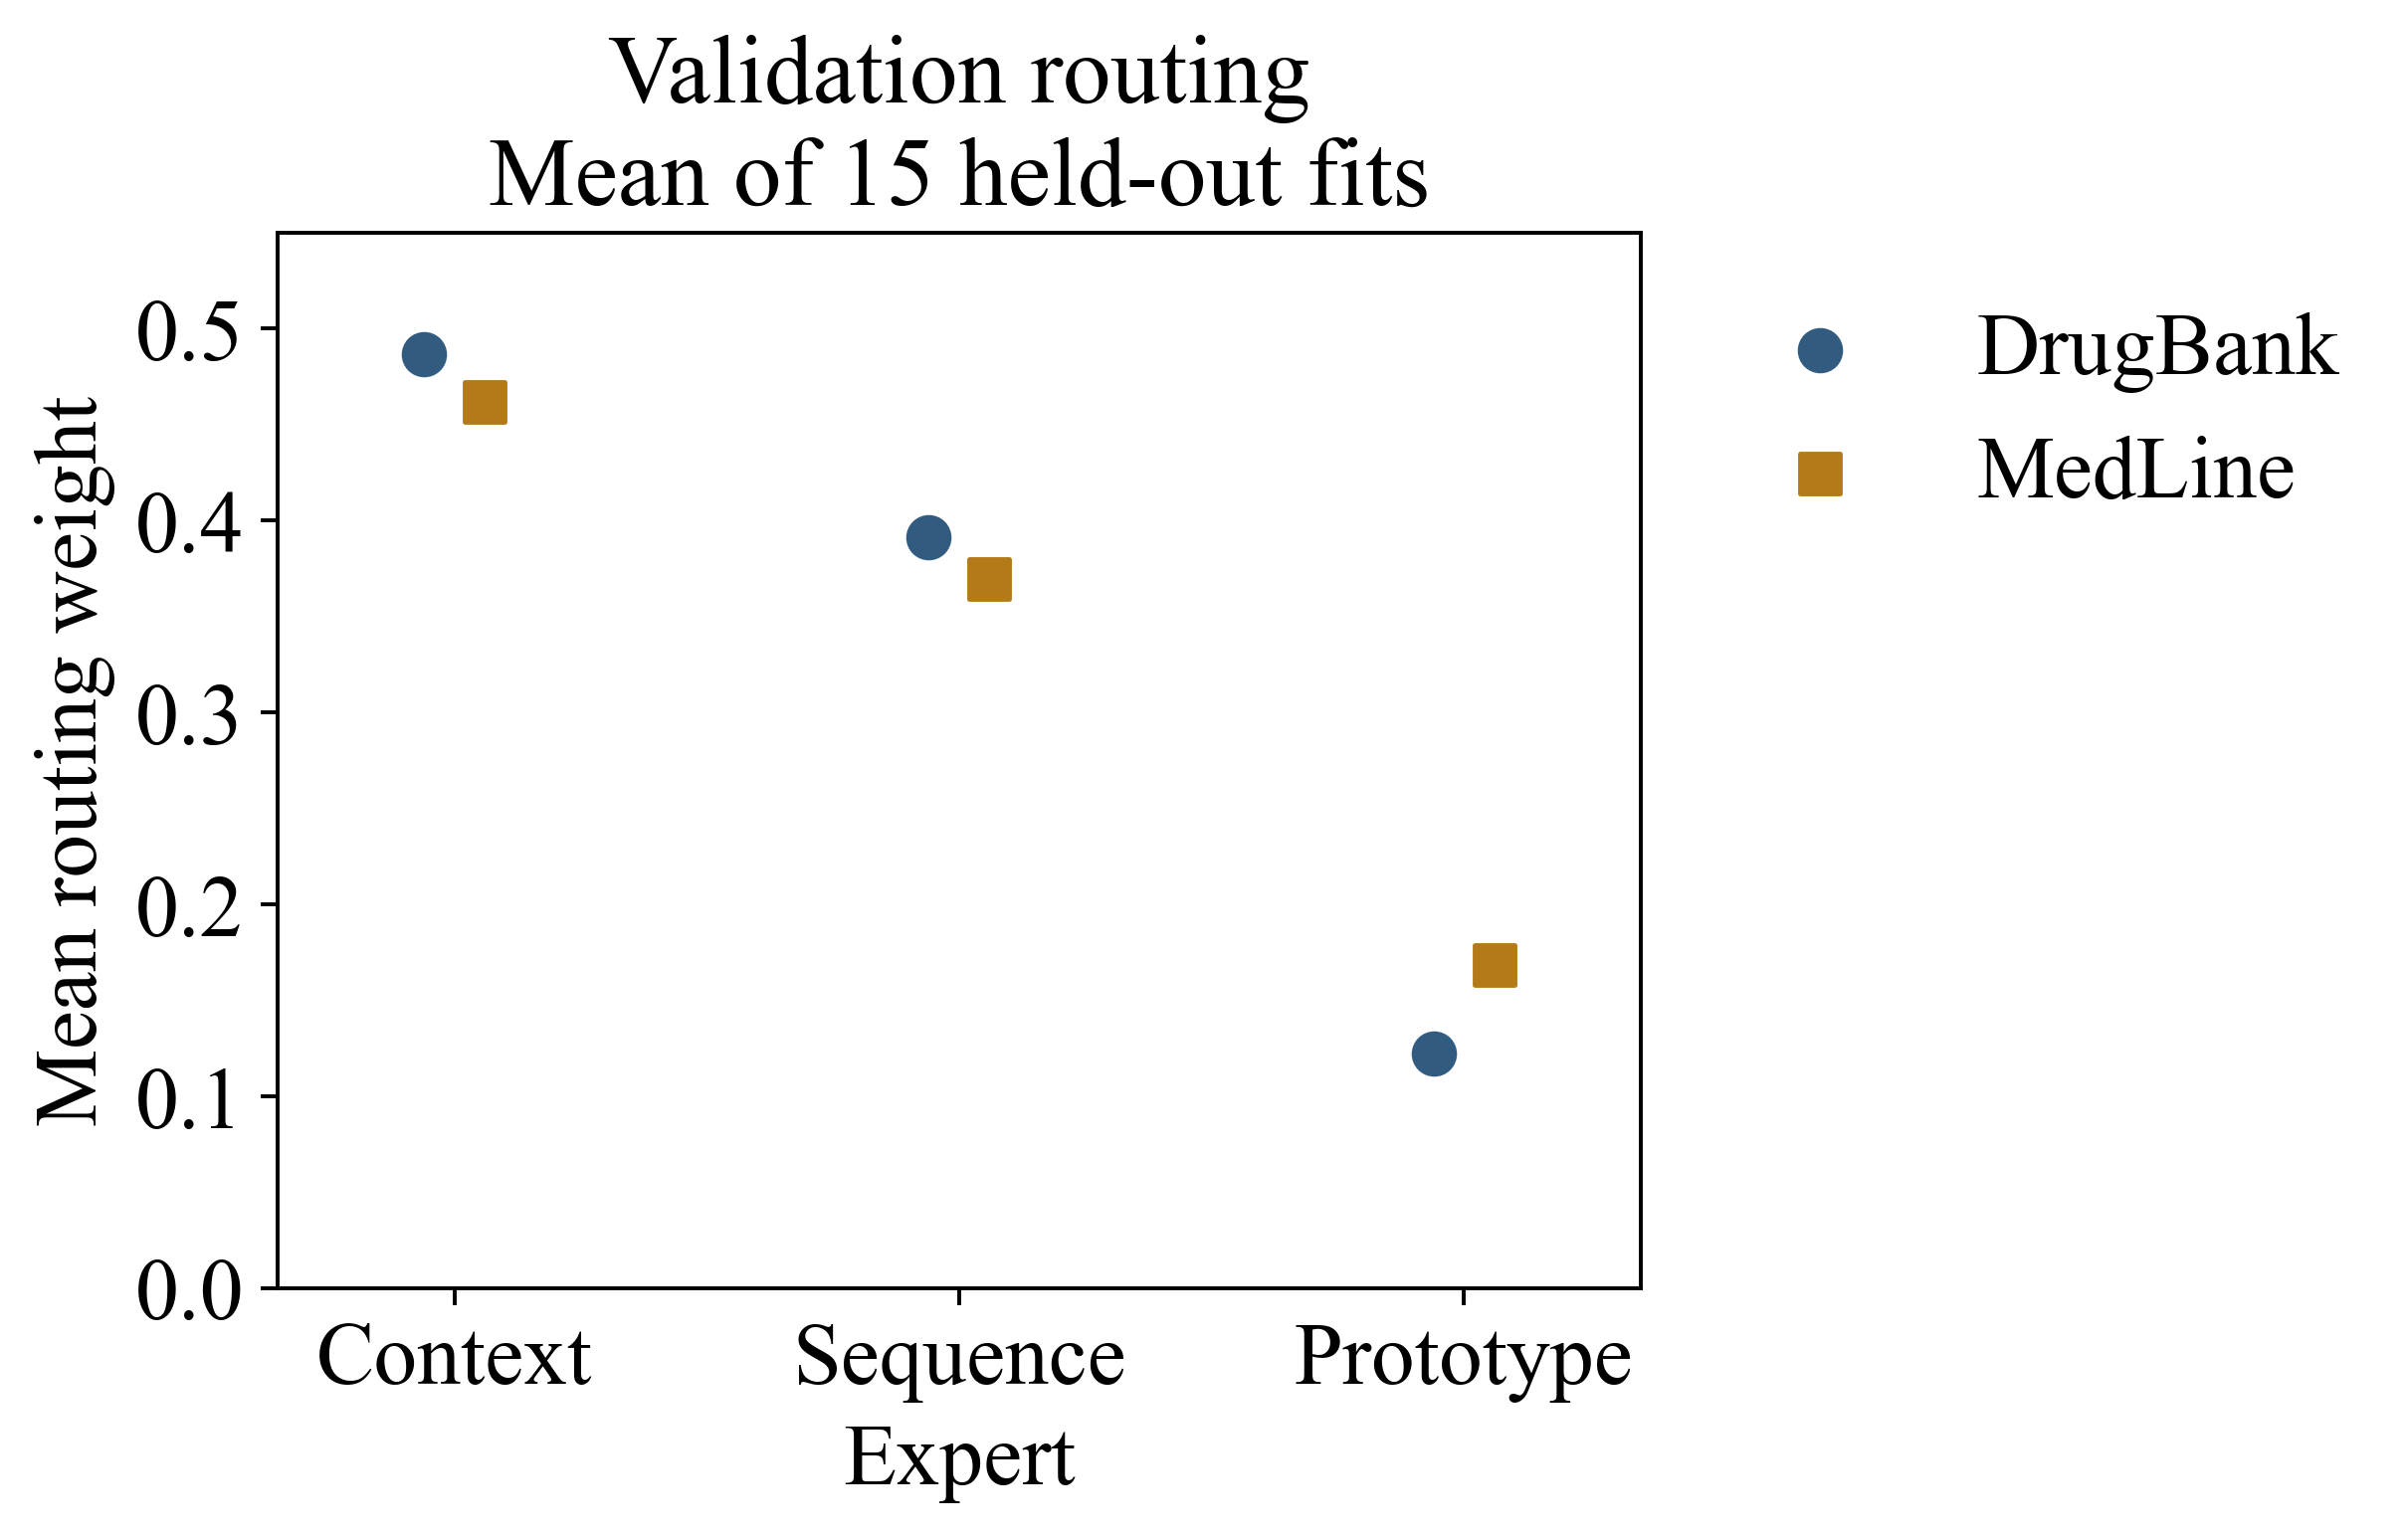

In [56]:
plot_data=routing.query("Dimension == 'Source'").groupby(["Group","Expert"],as_index=False)["Mean weight"].mean()
fit_count=routing[["Seed","Fold"]].drop_duplicates().shape[0]
experts=["context","sequence","prototype"]
fig,ax=plt.subplots(figsize=(6.8,4.3),layout="constrained")
for i,(source,group) in enumerate(plot_data.groupby("Group",sort=True)):
    values=group.set_index("Expert").loc[experts,"Mean weight"]
    ax.scatter(np.arange(3)+(i-.5)*.12,values,marker="o" if i==0 else "s",
        color=["#315C80","#B47A19"][i],s=70,label=source)
ax.set(xticks=range(3),xticklabels=["Context","Sequence","Prototype"],xlim=(-.35,2.35),
    xlabel="Expert",ylabel="Mean routing weight",
    title=f"Validation routing\nMean of {fit_count} held-out fits",ylim=(0,.55))
ax.legend(loc="upper left",bbox_to_anchor=(1.01,1),ncol=1,frameon=False)

mpl.rcParams["pdf.fonttype"]=42
fig.canvas.draw()
assert all(18<=label.get_fontsize()<=20 for label in fig.findobj(mpl.text.Text)
           if label.get_visible() and label.get_text().strip())
fig.savefig(PROJECT_ROOT/"figures/PNG/refinement_05_router_source.png",dpi=350,bbox_inches="tight",facecolor="white")
fig.savefig(PROJECT_ROOT/"figures/PDF/refinement_05_router_source.pdf",dpi=350,bbox_inches="tight",facecolor="white")
plot_data.to_csv(PROJECT_ROOT/"artifacts/refinement_05_router_source_source.csv",index=False)
plt.show()
plt.close(fig)

### Calibration

Does post-training calibration improve confidence without changing spans or types?

In [57]:
calibration_summary=summarize_seeds(seed_metrics,["raw_ece","ece","brier"])
calibration_summary=calibration_summary.rename(columns={"raw_ece":"Product-score ECE",
    "ece":"Stored-confidence ECE","brier":"Stored-confidence Brier"})
calibration_summary.to_csv(PROJECT_ROOT/"artifacts/refinement_05_calibration.csv",index=False)
display(calibration_summary.style.hide(axis="index"))

Model,Split,N,Seeds,Product-score ECE,Stored-confidence ECE,Stored-confidence Brier
Full ACT-NER,Validation cross-fit,2915,3,0.0299 ± 0.0035,0.0434 ± 0.0068,0.0711 ± 0.0050
Without Context Expert,Validation cross-fit,2915,3,0.0608 ± 0.0059,0.1656 ± 0.0272,0.1773 ± 0.0182
Without Sequence Expert,Validation cross-fit,2915,3,0.0212 ± 0.0054,0.0533 ± 0.0079,0.0872 ± 0.0051
Without Prototype Expert,Validation cross-fit,2915,3,0.0250 ± 0.0036,0.0505 ± 0.0165,0.0754 ± 0.0075
Static routing,Validation cross-fit,2915,3,0.0259 ± 0.0018,0.0573 ± 0.0094,0.0791 ± 0.0016
Without orthographic residual,Validation cross-fit,2915,3,0.0284 ± 0.0059,0.0511 ± 0.0115,0.0763 ± 0.0046
Without lexical reliability,Validation cross-fit,2915,3,0.0310 ± 0.0036,0.0655 ± 0.0194,0.0833 ± 0.0104
Without weak-signal recovery,Validation cross-fit,2915,3,0.0339 ± 0.0070,0.0686 ± 0.0296,0.0828 ± 0.0139
Without hard-negative mining,Validation cross-fit,2915,3,0.0261 ± 0.0017,0.0509 ± 0.0100,0.0751 ± 0.0030
Without class balancing,Validation cross-fit,2915,3,0.0302 ± 0.0036,0.0804 ± 0.0323,0.0924 ± 0.0188


Product-score ECE evaluates boundary_probability × type_probability. For refitted ACT-NER controls, stored confidence uses a map fitted on separate calibration documents; emitted spans and types remain unchanged. For frozen comparators, stored confidence is the original uncalibrated geometric-mean score, not the result of a post-training calibrator. Their two ECE columns therefore compare score definitions, not before/after calibration. Each row evaluates its own emitted-entity population.

### Domain, surface-form and length robustness

Does overall performance conceal subgroup deterioration?

In [58]:
subgroups=subgroup_evidence(PROJECT_ROOT,predictions,sentences,entities,tokens)
subgroups.to_csv(PROJECT_ROOT/"artifacts/refinement_05_subgroups.csv",index=False)
subgroup_summary=subgroups.groupby(["Model","Subgroup"],sort=False).agg(N=("N","first"),
    Typed_F1=("typed_f1","mean"),Seed_SD=("typed_f1","std"),Boundary_F1=("boundary_f1","mean"))
display(subgroup_summary.style.format(precision=4,na_rep="Not repeated"))

Seen/unseen is defined against the original Train lexicon. Source comparisons are internal domain analyses, not independent external validation.

### Paired statistical evidence

Is the corpus-level gain supported after document-cluster resampling and multiplicity correction?

In [59]:
comparisons=[("Full ACT-NER","Linear-chain CRF"),("Full ACT-NER","Biomedical Transformer")]
statistical_evidence=paired_evidence(predictions,sentences,entities,documents,comparisons)
statistical_evidence.to_csv(PROJECT_ROOT/"artifacts/refinement_05_statistics.csv",index=False)
display(statistical_evidence[["Comparison","N documents","Clusters","Micro-F1 difference","CI low","CI high","Micro-F1 Holm p"]].style.format(precision=5).hide(axis="index"))

Comparison,N documents,Clusters,Micro-F1 difference,CI low,CI high,Micro-F1 Holm p
Full ACT-NER − Linear-chain CRF,142,140,0.04153,0.02275,0.06406,0.00040
Full ACT-NER − Biomedical Transformer,142,140,0.05394,0.03372,0.07598,0.00040


In [60]:
display(statistical_evidence[["Comparison","Mean cluster-F1 difference","Rank-biserial effect","Wilcoxon Holm p"]].style.format(precision=5).hide(axis="index"))

Comparison,Mean cluster-F1 difference,Rank-biserial effect,Wilcoxon Holm p
Full ACT-NER − Linear-chain CRF,0.05993,0.55213,0.00000
Full ACT-NER − Biomedical Transformer,0.04768,0.58888,0.00000


The primary estimand is the difference in corpus micro-F1, averaged over seeds. Cluster-wise F1 and Wilcoxon are separate secondary estimands; repeated predictions are not independent documents.

### Component contributions

Which single-component removals alter performance under paired refitting?

In [61]:
ablation_pairs=[("Full ACT-NER",name) for name in predictions if name not in MODELS and name!="Full ACT-NER"]
component_evidence=paired_evidence(predictions,sentences,entities,documents,ablation_pairs)
component_evidence.to_csv(PROJECT_ROOT/"artifacts/refinement_05_component_statistics.csv",index=False)
display(component_evidence[["Comparison","Micro-F1 difference","CI low","CI high","Micro-F1 Holm p"]].style.format(precision=5).hide(axis="index"))

Comparison,Micro-F1 difference,CI low,CI high,Micro-F1 Holm p
Full ACT-NER − Without Context Expert,0.12239,0.09779,0.14899,0.00260
Full ACT-NER − Without Sequence Expert,0.01356,0.00480,0.02369,0.00480
Full ACT-NER − Without Prototype Expert,0.00460,-0.00113,0.01097,1.00000
Full ACT-NER − Static routing,0.00198,-0.00212,0.00626,1.00000
Full ACT-NER − Without orthographic residual,0.00172,-0.00106,0.00479,1.00000
Full ACT-NER − Without lexical reliability,0.00244,-0.00223,0.00753,1.00000
Full ACT-NER − Without weak-signal recovery,0.00039,-0.00300,0.00388,1.00000
Full ACT-NER − Without hard-negative mining,-0.00113,-0.00533,0.00303,1.00000
Full ACT-NER − Without class balancing,0.00576,0.00127,0.01020,0.19136
Full ACT-NER − Without source balancing,0.00408,-0.00114,0.00994,1.00000


Positive differences favour the full model; intervals spanning zero do not establish a component benefit. Components with unsupported or adverse effects are not credited as demonstrated improvements.

### Joint sensitivity and learning trajectories

How sensitive is inner-selection performance to joint settings and training epochs?

In [62]:
selection=pd.concat([pd.read_csv(run_directory/f"selection_fold_{fold}.csv") for fold in range(5)],ignore_index=True)
sensitivity=selection.groupby("configuration").selection_typed_f1.agg(["mean","std","min","max"])
sensitivity.to_csv(PROJECT_ROOT/"artifacts/refinement_05_joint_sensitivity.csv")
display(sensitivity.style.format(precision=4))

,mean,std,min,max
configuration,,,,
Joint-A,0.9240,0.0240,0.8750,0.9669
Joint-B,0.9242,0.0242,0.8719,0.9613
Joint-C,0.9132,0.0280,0.8640,0.9562


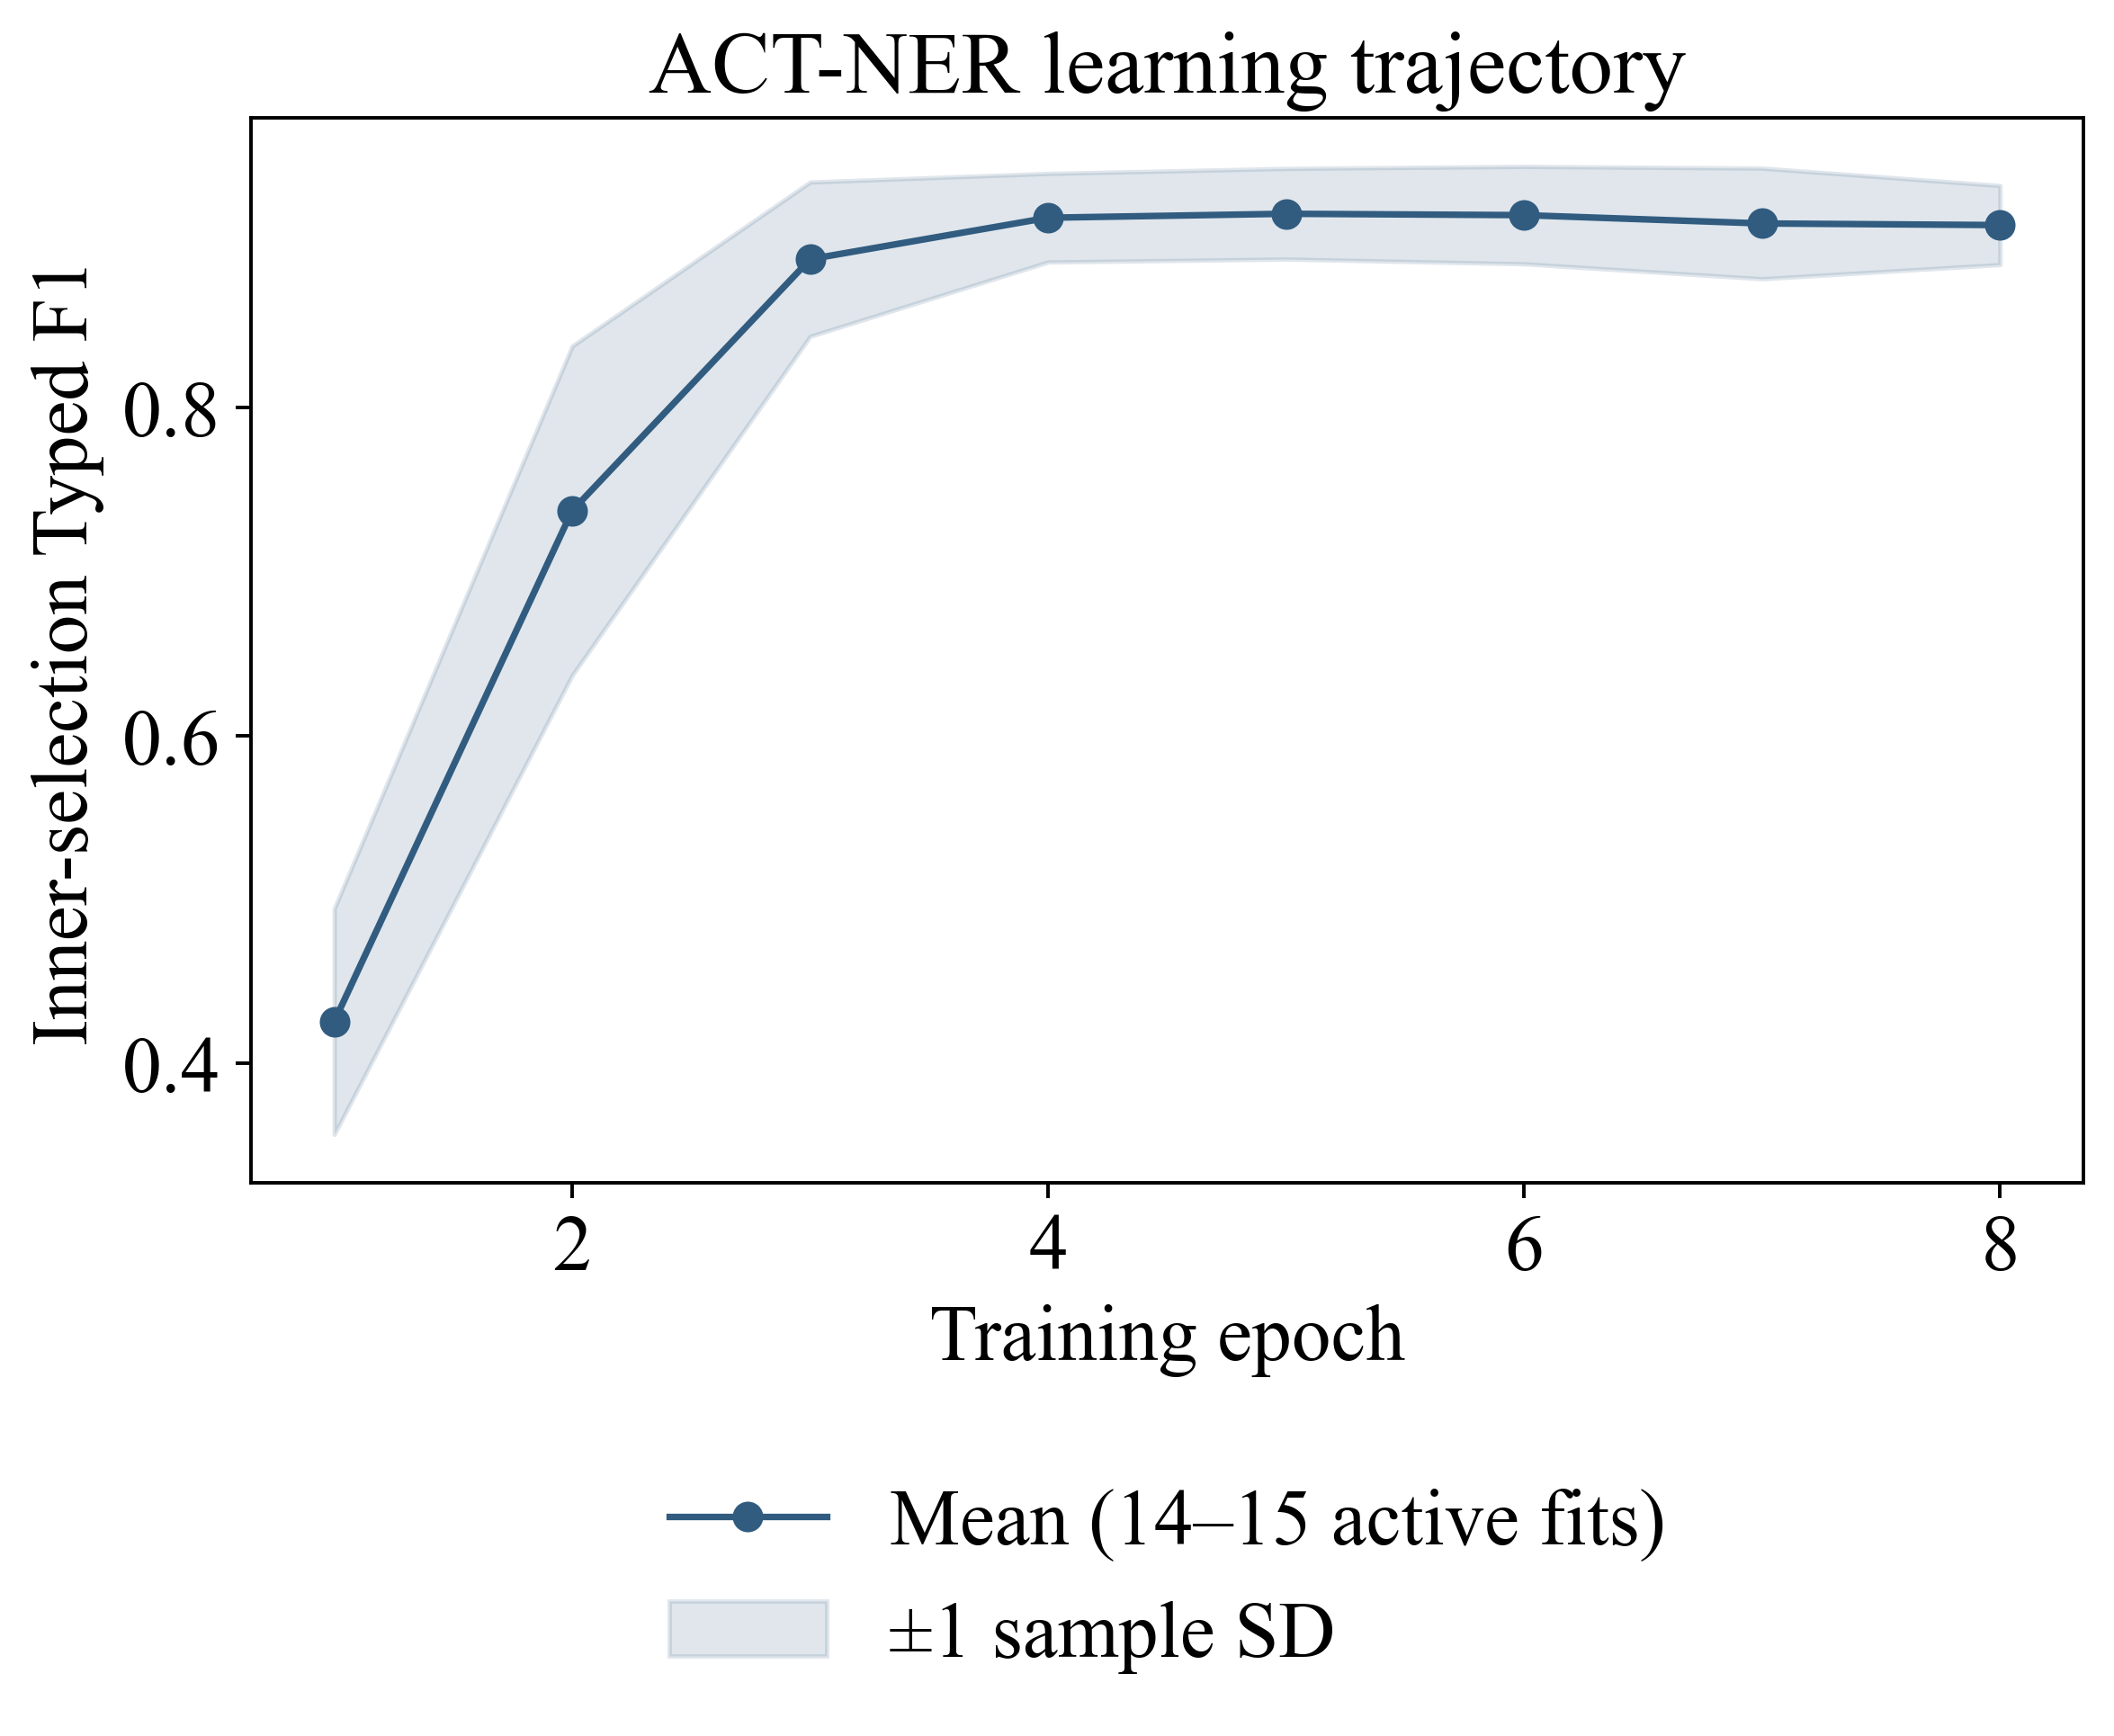

In [63]:
plot_data=histories.query("Model == 'Full ACT-NER'").groupby("epoch",as_index=False).agg(
    Selection_F1=("selection_typed_f1","mean"),SD=("selection_typed_f1","std"),Fits=("Fold","size"))
fig,ax=plt.subplots(figsize=(6.6,5.4),layout="constrained")
support=f"{int(plot_data.Fits.min())}–{int(plot_data.Fits.max())} active fits"
ax.plot(plot_data.epoch,plot_data.Selection_F1,"o-",color="#315C80",label=f"Mean ({support})")
ax.fill_between(plot_data.epoch,plot_data.Selection_F1-plot_data.SD.fillna(0),
    plot_data.Selection_F1+plot_data.SD.fillna(0),color="#315C80",alpha=0.15,label="±1 sample SD")
ax.set(xlabel="Training epoch",ylabel="Inner-selection Typed F1",title="ACT-NER learning trajectory")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=1,frameon=False)

mpl.rcParams["pdf.fonttype"]=42
fig.canvas.draw()
assert all(18<=label.get_fontsize()<=20 for label in fig.findobj(mpl.text.Text)
           if label.get_visible() and label.get_text().strip())
fig.savefig(PROJECT_ROOT/"figures/PNG/refinement_05_learning.png",dpi=350,bbox_inches="tight",facecolor="white")
fig.savefig(PROJECT_ROOT/"figures/PDF/refinement_05_learning.pdf",dpi=350,bbox_inches="tight",facecolor="white")
plot_data.to_csv(PROJECT_ROOT/"artifacts/refinement_05_learning_source.csv",index=False)
plt.show()
plt.close(fig)

The band describes variation between fits still active at each epoch; early stopping changes later-epoch support. The joint screen does not identify independent effects of dropout, loss and router size.

### Refit cost and matched-capacity control

What computation and trainable capacity accompany the component comparisons?

In [64]:
fit_cost=pd.concat(fold_results,ignore_index=True)
fit_cost["Head ms per sentence"]=1000*fit_cost.head_inference_seconds/fit_cost.sentences
capacity=fit_cost.groupby("configuration",sort=False).agg(Fits=("seed","size"),
    Minimum_parameters=("parameters","min"),Maximum_parameters=("parameters","max"),
    Mean_fit_seconds=("training_seconds","mean"),Fit_seconds_SD=("training_seconds","std"))
capacity.to_csv(PROJECT_ROOT/"artifacts/refinement_05_capacity_and_fit_cost.csv")
display(capacity.style.format(precision=2))

,Fits,Minimum_parameters,Maximum_parameters,Mean_fit_seconds,Fit_seconds_SD
configuration,,,,,
Full ACT-NER,15,363291,374811,28.91,4.75
Without Context Expert,15,363291,374811,25.86,5.27
Without Sequence Expert,15,363291,374811,26.90,5.25
Without Prototype Expert,15,363291,374811,23.21,5.33
Static routing,15,363291,374811,23.41,4.29
Without orthographic residual,15,363291,374811,25.59,4.58
Without lexical reliability,15,363291,374811,26.22,4.87
Without weak-signal recovery,15,363291,374811,23.82,4.25
Without hard-negative mining,15,363291,374811,28.10,4.38


In [65]:
head_cost=fit_cost.groupby("configuration",sort=False).agg(Fits=("seed","size"),
    Mean_ms_per_sentence=("Head ms per sentence","mean"),SD_ms_per_sentence=("Head ms per sentence","std"))
head_cost.to_csv(PROJECT_ROOT/"artifacts/refinement_05_cached_head_cost.csv")
display(head_cost.style.format(precision=3))

,Fits,Mean_ms_per_sentence,SD_ms_per_sentence
configuration,,,
Full ACT-NER,15,1.190,0.577
Without Context Expert,15,0.883,0.420
Without Sequence Expert,15,0.808,0.166
Without Prototype Expert,15,0.579,0.096
Static routing,15,0.612,0.082
Without orthographic residual,15,0.767,0.147
Without lexical reliability,15,0.781,0.176
Without weak-signal recovery,15,0.667,0.090
Without hard-negative mining,15,0.796,0.233


Fit time includes training and inner epoch/threshold selection. Head scoring uses cached expert features and excludes expert inference and decoding. Parameter ranges reflect the jointly selected setting in each fold. These shared-device timings do not establish an end-to-end speed advantage over the frozen comparators.

## Final development fit and freeze

Can the complete prediction and confidence policy be fixed before test inference?

In [66]:
progress_handle=display(HTML(""),display_id=True)
training_started=time.perf_counter()
def training_progress(fold,configuration,seed,row):
    minutes=(time.perf_counter()-training_started)/60
    progress_handle.update(HTML(
        f"<div style='font-family:Times New Roman;font-size:18px;padding:6px'>"
        f"ACT-NER · fold {fold+1 if fold>=0 else 'final'} · {configuration} · seed {seed}<br>"
        f"Epoch {row['epoch']} · training loss {row['train_loss']:.4f} · "
        f"inner-selection Typed F1 {row['selection_typed_f1']:.4f} · {minutes:.1f} min</div>"))

In [67]:
final_fits=freeze_final(PROJECT_ROOT,bundle,sentences,entities,documents,fold_results,training_progress)
progress_handle.update(HTML(""))
final_policy=final_fits[["seed","epoch","threshold","selection_typed_f1","parameters","noncollapsed_router"]]
final_policy.to_csv(PROJECT_ROOT/"artifacts/refinement_05_final_policy.csv",index=False)
display(final_policy.style.format(precision=4).hide(axis="index"))
assert set(final_fits.seed)==set(SEEDS)
assert len(fold_results)==5

seed,epoch,threshold,selection_typed_f1,parameters,noncollapsed_router
17,6,0.2500,0.9390,363291,True
29,5,0.2500,0.9401,363291,True
43,5,0.6000,0.9363,363291,True


The exported model uses the predeclared reference seed 17, not the best seed. Its checkpoint, recognition threshold and calibrator are sealed for Notebook 06. No test performance is used to revise this configuration.